In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

def show(markdown_text):
    """Render a dynamically-built string as Markdown output, so numeric findings
    are generated by code rather than typed into a static Markdown cell."""
    display(Markdown(markdown_text))


In [2]:
candidate_paths = [
    Path("../data/raw/data_FraudDetection_JAR2020.csv"),
    Path("data/raw/data_FraudDetection_JAR2020.csv"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not locate data_FraudDetection_JAR2020.csv in either "
        f"{candidate_paths[0]} or {candidate_paths[1]}. "
        "Confirm the file has been placed in data/raw/."
    )

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy()  # working copy; df_raw is never modified below

show(
    f"**Loaded:** `{DATA_PATH}`  \n"
    f"**Shape:** {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns  \n"
    f"**Memory usage:** {df_raw.memory_usage(deep=True).sum() / 1e6:.2f} MB"
)


**Loaded:** `..\data\raw\data_FraudDetection_JAR2020.csv`  
**Shape:** 146,045 rows x 46 columns  
**Memory usage:** 53.74 MB

In [3]:
n_rows = len(df)
n_unique_gvkey_fyear = df.drop_duplicates(subset=["gvkey", "fyear"]).shape[0]
n_unique_gvkey = df["gvkey"].nunique()
n_unique_fyear = df["fyear"].nunique()
n_missing_gvkey = df["gvkey"].isna().sum()
n_missing_fyear = df["fyear"].isna().sum()
n_dupe_gvkey_fyear = n_rows - n_unique_gvkey_fyear

show(
    f"| Check | Result |\n|---|---|\n"
    f"| Total rows | {n_rows:,} |\n"
    f"| Unique (gvkey, fyear) combinations | {n_unique_gvkey_fyear:,} |\n"
    f"| Rows minus unique (gvkey, fyear) combos | {n_dupe_gvkey_fyear} |\n"
    f"| Unique gvkey values (companies) | {n_unique_gvkey:,} |\n"
    f"| Unique fyear values | {n_unique_fyear} |\n"
    f"| Missing gvkey values | {n_missing_gvkey} |\n"
    f"| Missing fyear values | {n_missing_fyear} |"
)


| Check | Result |
|---|---|
| Total rows | 146,045 |
| Unique (gvkey, fyear) combinations | 146,045 |
| Rows minus unique (gvkey, fyear) combos | 0 |
| Unique gvkey values (companies) | 18,444 |
| Unique fyear values | 25 |
| Missing gvkey values | 0 |
| Missing fyear values | 0 |

In [4]:
row_grain_conclusion = (
    "SUPPORTED: each row represents one company-fiscal-year observation "
    "(rows exactly match unique (gvkey, fyear) combinations, and neither "
    "identifier has missing values)."
    if n_dupe_gvkey_fyear == 0 and n_missing_gvkey == 0 and n_missing_fyear == 0
    else "NOT CONFIRMED: rows do not cleanly map to unique (gvkey, fyear) pairs, "
    "or one of the identifiers has missing values — this needs further investigation "
    "before assuming a company-year grain."
)
show(f"**Row-grain conclusion (based on the results above):** {row_grain_conclusion}")


**Row-grain conclusion (based on the results above):** SUPPORTED: each row represents one company-fiscal-year observation (rows exactly match unique (gvkey, fyear) combinations, and neither identifier has missing values).

In [5]:
dims_summary = pd.DataFrame({
    "Metric": [
        "Number of rows",
        "Number of columns",
        "Numerical columns (int/float)",
        "Object/categorical columns",
        "Boolean columns",
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df.select_dtypes(include=[np.number]).shape[1],
        df.select_dtypes(include=["object"]).shape[1],
        df.select_dtypes(include=["bool"]).shape[1],
    ]
})
dims_summary


,Metric,Value
0,Number of rows,146045
1,Number of columns,46
2,Numerical columns (int/float),46
3,Object/categorical columns,0
4,Boolean columns,0


In [6]:
def example_value(series):
    non_null = series.dropna()
    return non_null.iloc[0] if len(non_null) > 0 else None

inventory = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "n_unique": [df[c].nunique() for c in df.columns],
    "missing_count": df.isna().sum().values,
})
inventory["missing_pct"] = (inventory["missing_count"] / len(df) * 100).round(2)
inventory["example_value"] = [example_value(df[c]) for c in df.columns]
inventory = inventory.reset_index(drop=True)
inventory


,column,dtype,n_unique,missing_count,missing_pct,example_value
0,fyear,int64,25,0,0.000,"1,990.000"
1,gvkey,int64,18444,0,0.000,"1,009.000"
2,p_aaer,float64,412,145081,99.340,789.000
3,misstate,int64,2,0,0.000,0.000
4,act,float64,97571,0,0.000,10.047
5,ap,float64,57339,0,0.000,3.736
6,at,float64,114109,0,0.000,32.335
7,ceq,float64,106764,0,0.000,6.262
8,che,float64,64462,0,0.000,0.002
9,cogs,float64,99003,0,0.000,30.633


## 6. Missing values

In [7]:
# Empirical verification of `issue`: the authors describe it as an "actual issuance" flag.
# Test whether it aligns with a firm having positive long-term debt issuance (dltis)
# or positive stock sale proceeds (sstk) in the same year.
implied_issue = ((df["dltis"].fillna(0) > 0) | (df["sstk"].fillna(0) > 0)).astype(int)
agreement = (implied_issue == df["issue"]).mean()

show(f"**Agreement between `issue` and `(dltis>0 or sstk>0)`:** {agreement:.4%}")
pd.crosstab(df["issue"], implied_issue, rownames=["issue"], colnames=["implied (dltis>0 or sstk>0)"])


**Agreement between `issue` and `(dltis>0 or sstk>0)`:** 100.0000%

implied (dltis>0 or sstk>0),0,1
issue,,
0,19937,0
1,0,126108


In [8]:
# Empirical verification of p_aaer's relationship to misstate (also revisited in Section 23,
# since it is central to the data-leakage assessment).
n_paaer_notna = df["p_aaer"].notna().sum()
n_misstate_1 = (df["misstate"] == 1).sum()
n_paaer_notna_misstate_0 = ((df["p_aaer"].notna()) & (df["misstate"] == 0)).sum()
n_paaer_na_misstate_1 = ((df["p_aaer"].isna()) & (df["misstate"] == 1)).sum()

show(
    f"| Check | Count |\n|---|---|\n"
    f"| `p_aaer` non-null | {n_paaer_notna:,} |\n"
    f"| `misstate == 1` | {n_misstate_1:,} |\n"
    f"| `p_aaer` non-null AND `misstate == 0` | {n_paaer_notna_misstate_0} |\n"
    f"| `p_aaer` null AND `misstate == 1` | {n_paaer_na_misstate_1} |"
)


| Check | Count |
|---|---|
| `p_aaer` non-null | 964 |
| `misstate == 1` | 964 |
| `p_aaer` non-null AND `misstate == 0` | 0 |
| `p_aaer` null AND `misstate == 1` | 0 |

In [9]:
obs_per_company = df.groupby("gvkey").size()

id_summary = pd.DataFrame({
    "Metric": ["Unique companies (gvkey)", "Min obs/company", "25th pct", "Median",
               "75th pct", "Max obs/company", "Mean obs/company"],
    "Value": [
        df["gvkey"].nunique(),
        obs_per_company.min(),
        obs_per_company.quantile(0.25),
        obs_per_company.median(),
        obs_per_company.quantile(0.75),
        obs_per_company.max(),
        round(obs_per_company.mean(), 2),
    ]
})
id_summary


,Metric,Value
0,Unique companies (gvkey),"18,444.000"
1,Min obs/company,1.000
2,25th pct,3.000
3,Median,6.000
4,75th pct,11.000
5,Max obs/company,25.000
6,Mean obs/company,7.920


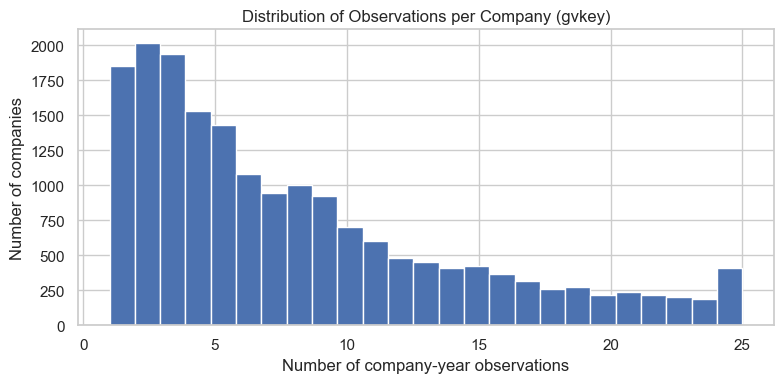

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
obs_per_company.plot(kind="hist", bins=25, ax=ax, edgecolor="white")
ax.set_xlabel("Number of company-year observations")
ax.set_ylabel("Number of companies")
ax.set_title("Distribution of Observations per Company (gvkey)")
plt.tight_layout()
plt.show()


In [11]:
year_summary = df.groupby("fyear").agg(
    n_obs=("gvkey", "size"),
    n_companies=("gvkey", "nunique"),
    n_positive=("misstate", "sum"),
)
year_summary["positive_rate_pct"] = (year_summary["n_positive"] / year_summary["n_obs"] * 100).round(3)

print(f"Earliest fiscal year: {df['fyear'].min()}")
print(f"Latest fiscal year: {df['fyear'].max()}")
print(f"Number of distinct fiscal years: {df['fyear'].nunique()}")
year_summary


Earliest fiscal year: 1990
Latest fiscal year: 2014
Number of distinct fiscal years: 25


,n_obs,n_companies,n_positive,positive_rate_pct
fyear,,,,
1990,4582,4582,15,0.327
1991,4713,4713,27,0.573
1992,4970,4970,26,0.523
1993,5377,5377,30,0.558
1994,5684,5684,23,0.405
1995,6230,6230,22,0.353
1996,6745,6745,33,0.489
1997,6789,6789,42,0.619
1998,6716,6716,56,0.834


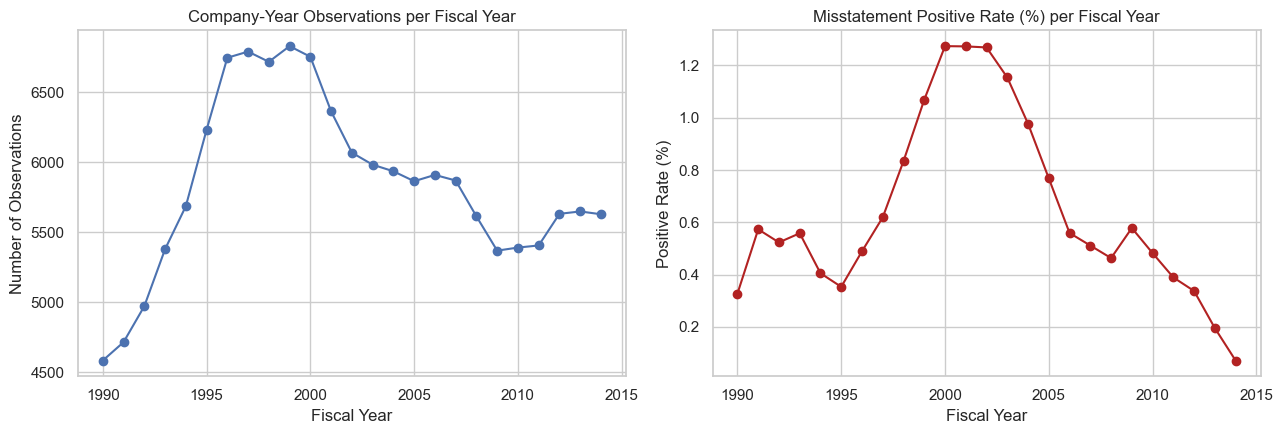

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(year_summary.index, year_summary["n_obs"], marker="o")
axes[0].set_title("Company-Year Observations per Fiscal Year")
axes[0].set_xlabel("Fiscal Year")
axes[0].set_ylabel("Number of Observations")

axes[1].plot(year_summary.index, year_summary["positive_rate_pct"], marker="o", color="firebrick")
axes[1].set_title("Misstatement Positive Rate (%) per Fiscal Year")
axes[1].set_xlabel("Fiscal Year")
axes[1].set_ylabel("Positive Rate (%)")

plt.tight_layout()
plt.show()



In [13]:
peak_obs_year = year_summary["n_obs"].idxmax()
min_obs_year = year_summary["n_obs"].idxmin()
peak_rate_year = year_summary["positive_rate_pct"].idxmax()
min_rate_year = year_summary["positive_rate_pct"].idxmin()

show(
    f"**Year with most observations:** {peak_obs_year} ({year_summary.loc[peak_obs_year, 'n_obs']:,} rows)  \n"
    f"**Year with fewest observations:** {min_obs_year} ({year_summary.loc[min_obs_year, 'n_obs']:,} rows)  \n"
    f"**Year with highest positive rate:** {peak_rate_year} ({year_summary.loc[peak_rate_year, 'positive_rate_pct']:.3f}%)  \n"
    f"**Year with lowest positive rate:** {min_rate_year} ({year_summary.loc[min_rate_year, 'positive_rate_pct']:.3f}%)"
)


**Year with most observations:** 1999 (6,828 rows)  
**Year with fewest observations:** 1990 (4,582 rows)  
**Year with highest positive rate:** 2000 (1.274%)  
**Year with lowest positive rate:** 2014 (0.071%)

In [14]:
target_counts = df["misstate"].value_counts(dropna=False)
target_pct = df["misstate"].value_counts(normalize=True, dropna=False) * 100
n_missing_target = df["misstate"].isna().sum()

target_summary = pd.DataFrame({"count": target_counts, "pct": target_pct.round(3)})

show(f"**Missing target values:** {n_missing_target}")
target_summary


**Missing target values:** 0

,count,pct
misstate,,
0,145081,99.340
1,964,0.660


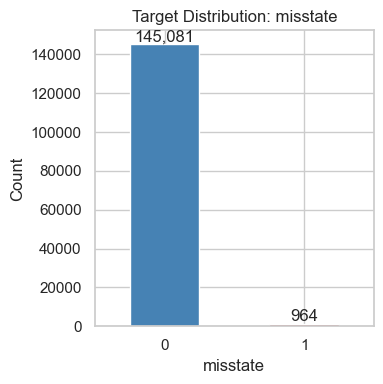

In [15]:
fig, ax = plt.subplots(figsize=(4, 4))
target_counts.plot(kind="bar", ax=ax, color=["steelblue", "firebrick"])
ax.set_xticklabels([str(i) for i in target_counts.index], rotation=0)
ax.set_ylabel("Count")
ax.set_title("Target Distribution: misstate")
for i, v in enumerate(target_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()


In [16]:
n_pos = int(target_counts.get(1, 0))
n_neg = int(target_counts.get(0, 0))
pos_pct = target_pct.get(1, 0.0)

show(
    f"**Positive (historically AAER-associated) observations:** {n_pos:,} of {len(df):,} "
    f"({pos_pct:.3f}%)  \n"
    f"**Negative (no AAER association found) observations:** {n_neg:,}"
)


**Positive (historically AAER-associated) observations:** 964 of 146,045 (0.660%)  
**Negative (no AAER association found) observations:** 145,081

In [17]:
exact_dupes = df.duplicated(keep=False).sum()
gvkey_fyear_dupes = df.duplicated(subset=["gvkey", "fyear"], keep=False).sum()

dupe_summary = pd.DataFrame({
    "Check": ["Exact duplicate rows", "Duplicate (gvkey, fyear) combinations"],
    "Count": [exact_dupes, gvkey_fyear_dupes],
    "Pct of rows": [round(exact_dupes / len(df) * 100, 4), round(gvkey_fyear_dupes / len(df) * 100, 4)],
})
dupe_summary


,Check,Count,Pct of rows
0,Exact duplicate rows,0,0.000
1,"Duplicate (gvkey, fyear) combinations",0,0.000


In [18]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_table = missing_table[missing_table["missing_count"] > 0].sort_values("missing_pct", ascending=False)
missing_table


,missing_count,missing_pct
p_aaer,145081,99.340
ch_cm,17107,11.710
ch_cs,15918,10.900
ch_roa,12678,8.680
dpi,9228,6.320
ch_fcf,5407,3.700
ch_rsst,4851,3.320
dch_wc,4759,3.260
dch_rec,4743,3.250
dch_inv,4615,3.160


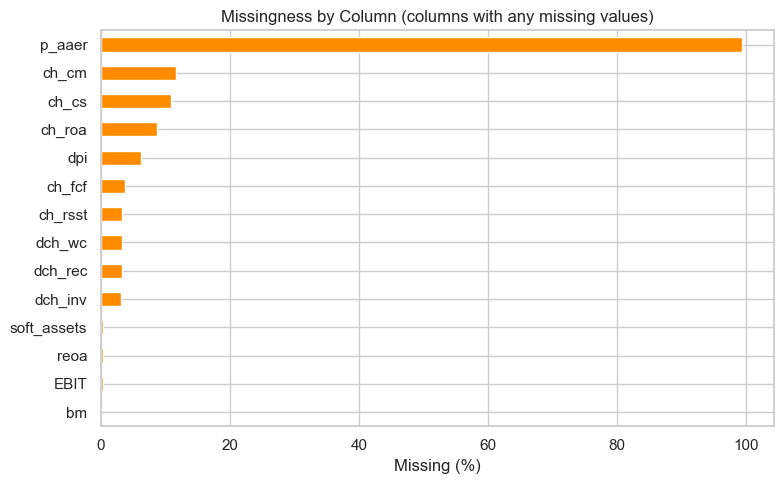

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
missing_table["missing_pct"].plot(kind="barh", ax=ax, color="darkorange")
ax.set_xlabel("Missing (%)")
ax.set_title("Missingness by Column (columns with any missing values)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


In [20]:
# Missingness by target: does missingness differ between positive and negative labels?
high_missing_cols = missing_table.index.tolist()
miss_by_target = df.groupby("misstate")[high_missing_cols].apply(lambda x: x.isna().mean() * 100).T
miss_by_target.columns = [f"missing_pct_misstate_{c}" for c in miss_by_target.columns]
miss_by_target.round(2)


,missing_pct_misstate_0,missing_pct_misstate_1
p_aaer,100.000,0.000
ch_cm,11.760,4.670
ch_cs,10.940,4.360
ch_roa,8.710,4.150
dpi,6.350,1.870
ch_fcf,3.710,2.070
ch_rsst,3.330,2.070
dch_wc,3.270,1.760
dch_rec,3.260,1.350
dch_inv,3.170,1.560


In [21]:
raw_vars = ["act","ap","at","ceq","che","cogs","csho","dlc","dltis","dltt","dp","ib",
            "invt","ivao","ivst","lct","lt","ni","ppegt","pstk","re","rect","sale","sstk",
            "txp","txt","xint","prcc_f"]
n_raw_with_missing = sum(1 for c in raw_vars if missing_table.index.__contains__(c))
n_cols_with_missing = len(missing_table)

show(
    f"**Columns with at least one missing value:** {n_cols_with_missing} of {df.shape[1]}  \n"
    f"**Of the 28 raw accounting variables, columns with any missing values:** {n_raw_with_missing}  \n"
    f"**Highest missingness column (excluding p_aaer):** "
    f"{missing_table.drop(index='p_aaer', errors='ignore')['missing_pct'].idxmax()} "
    f"({missing_table.drop(index='p_aaer', errors='ignore')['missing_pct'].max():.2f}%)"
)


**Columns with at least one missing value:** 14 of 46  
**Of the 28 raw accounting variables, columns with any missing values:** 0  
**Highest missingness column (excluding p_aaer):** ch_cm (11.71%)

In [22]:
ratio_vars = ["dch_wc","ch_rsst","dch_rec","dch_inv","soft_assets","ch_cs","ch_cm",
              "ch_roa","issue","bm","dpi","reoa","EBIT","ch_fcf"]

def profile_table(cols):
    rows = []
    for c in cols:
        s = df[c].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        rows.append({
            "variable": c, "count": s.count(), "mean": s.mean(), "median": s.median(),
            "std": s.std(), "min": s.min(), "Q1": q1, "Q3": q3, "IQR": q3 - q1, "max": s.max(),
        })
    return pd.DataFrame(rows).set_index("variable")

raw_profile = profile_table(raw_vars)
raw_profile


,count,mean,median,std,min,Q1,Q3,IQR,max
variable,,,,,,,,,
act,146045,737.848,47.501,"3,744.542",-0.254,8.277,249.832,241.555,"152,629.000"
ap,146045,181.993,6.462,"1,047.546",0.000,1.151,42.259,41.108,"39,903.000"
at,146045,"2,374.042",105.346,"11,957.737",0.000,18.281,672.929,654.648,"410,074.000"
ceq,146045,887.126,47.308,"5,056.948","-25,560.000",6.337,271.547,265.210,"284,434.000"
che,146045,218.657,9.373,"1,330.490",-34.000,1.144,60.286,59.142,"85,709.000"
cogs,146045,"1,302.281",53.382,"7,870.666",-366.645,6.795,372.730,365.935,"435,726.253"
csho,146045,97.005,22.540,540.875,0.000,8.796,60.736,51.940,"100,092.395"
dlc,146045,127.228,1.363,"1,023.092",-0.069,0.008,12.750,12.742,"75,553.000"
dltis,146045,201.312,0.063,"1,628.477",-19.687,0.000,24.873,24.873,"188,791.978"


In [23]:
ratio_profile = profile_table(ratio_vars)
ratio_profile


,count,mean,median,std,min,Q1,Q3,IQR,max
variable,,,,,,,,,
dch_wc,141286,-0.005,0.004,0.182,-1.000,-0.033,0.045,0.077,0.609
ch_rsst,141194,0.019,0.026,0.427,-2.072,-0.060,0.122,0.182,1.504
dch_rec,141302,0.013,0.005,0.083,-0.305,-0.010,0.035,0.045,0.383
dch_inv,141430,0.007,0.000,0.057,-0.222,-0.002,0.015,0.017,0.268
soft_assets,145453,0.500,0.525,0.274,0.005,0.270,0.727,0.457,0.994
ch_cs,130127,0.185,0.068,1.383,-6.484,-0.074,0.250,0.324,9.600
ch_cm,128938,-0.091,-0.023,2.845,-17.360,-0.260,0.140,0.400,16.574
ch_roa,133367,-0.010,-0.002,0.380,-1.672,-0.059,0.042,0.101,1.622
issue,146045,0.863,1.000,0.343,0.000,1.000,1.000,0.000,1.000


In [24]:
skew_check = (raw_profile["mean"] - raw_profile["median"]).abs().sort_values(ascending=False)
show(
    f"**Raw variable with the largest gap between mean and median (a simple skew signal):** "
    f"`{skew_check.index[0]}` (|mean - median| = {skew_check.iloc[0]:,.2f})"
)


**Raw variable with the largest gap between mean and median (a simple skew signal):** `at` (|mean - median| = 2,268.70)

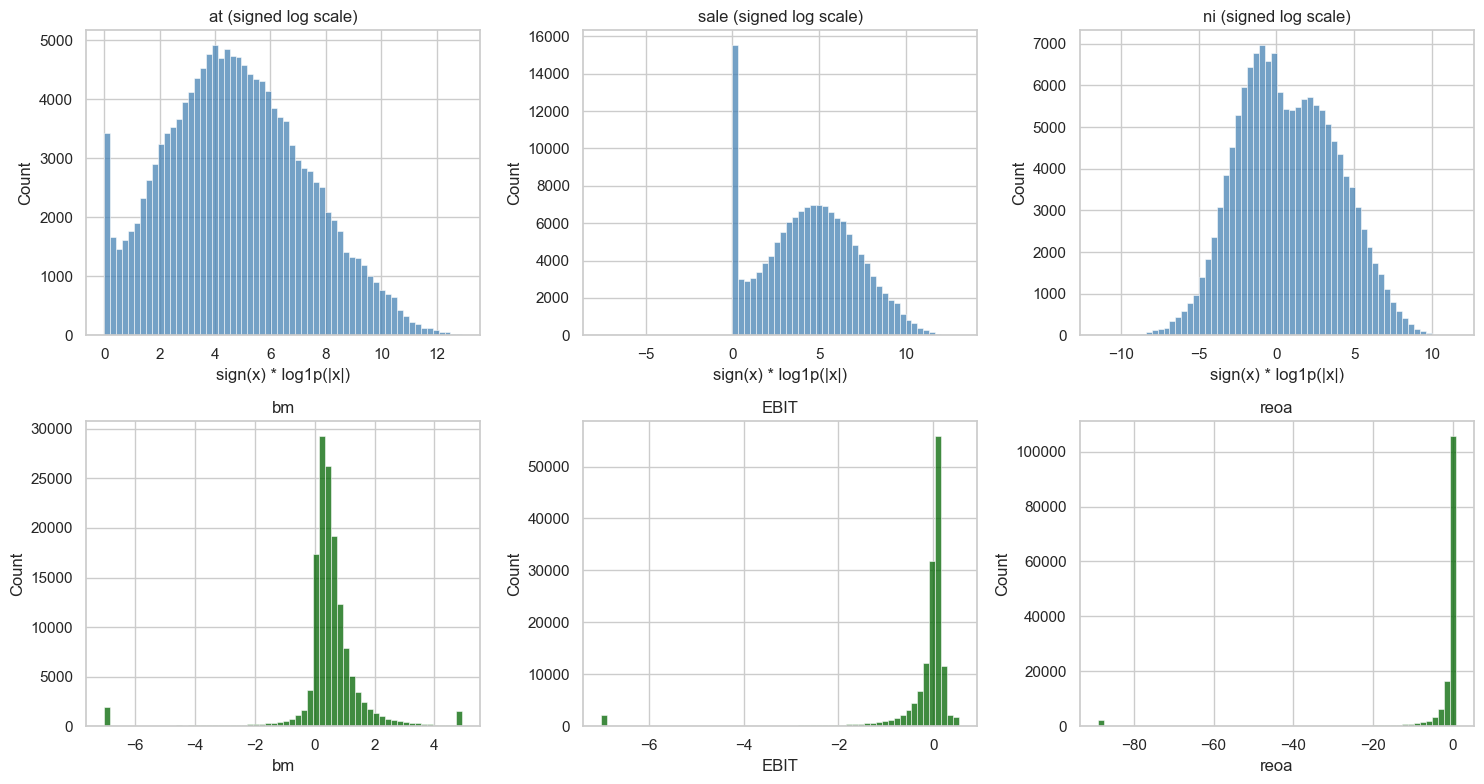

In [25]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

plot_vars_raw = ["at", "sale", "ni"]
for ax, col in zip(axes[0], plot_vars_raw):
    sns.histplot(signed_log(df[col].dropna()), bins=60, ax=ax, color="steelblue")
    ax.set_title(f"{col} (signed log scale)")
    ax.set_xlabel("sign(x) * log1p(|x|)")

plot_vars_ratio = ["bm", "EBIT", "reoa"]
for ax, col in zip(axes[1], plot_vars_ratio):
    sns.histplot(df[col].dropna(), bins=60, ax=ax, color="darkgreen")
    ax.set_title(col)

plt.tight_layout()
plt.show()


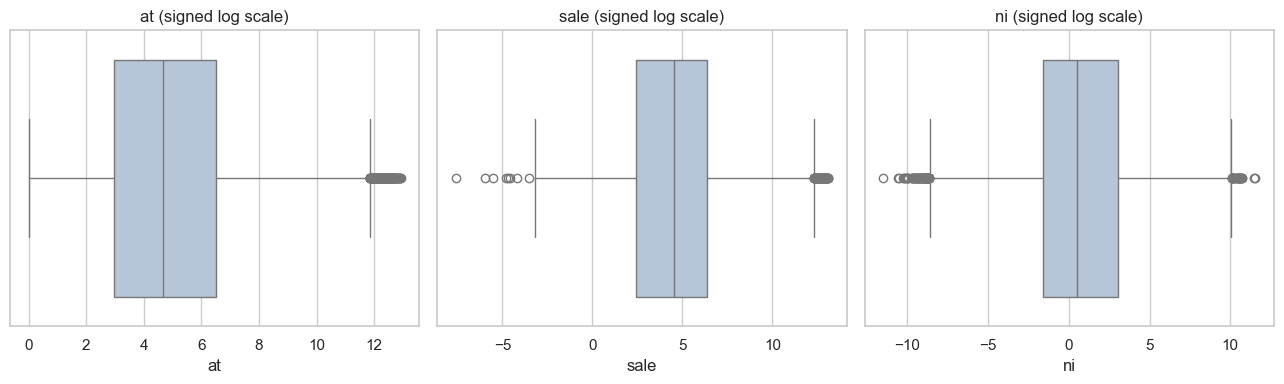

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["at", "sale", "ni"]):
    sns.boxplot(x=signed_log(df[col].dropna()), ax=ax, color="lightsteelblue")
    ax.set_title(f"{col} (signed log scale)")
plt.tight_layout()
plt.show()


In [27]:
def iqr_outlier_pct(col):
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((s < lower) | (s > upper)).sum()
    return n_outliers, round(n_outliers / len(s) * 100, 2)

outlier_rows = []
for c in raw_vars + ratio_vars:
    n, pct = iqr_outlier_pct(c)
    outlier_rows.append({"variable": c, "n_outliers_iqr": n, "pct_outliers_iqr": pct})

outlier_summary = pd.DataFrame(outlier_rows).sort_values("pct_outliers_iqr", ascending=False)
outlier_summary.head(15)


,variable,n_outliers_iqr,pct_outliers_iqr
20,re,36040,24.680
31,dch_inv,34446,24.360
17,ni,33859,23.180
11,ib,33469,22.920
13,ivao,30996,21.220
35,ch_roa,27882,20.910
34,ch_cm,26783,20.770
14,ivst,30164,20.650
25,txt,28744,19.680
8,dltis,28471,19.490


In [28]:
sign_rows = []
for c in raw_vars:
    s = df[c]
    sign_rows.append({
        "variable": c,
        "n_negative": (s < 0).sum(),
        "n_zero": (s == 0).sum(),
        "min": s.min(),
        "max": s.max(),
    })
sign_summary = pd.DataFrame(sign_rows).set_index("variable")
sign_summary


,n_negative,n_zero,min,max
variable,,,,
act,8,847,-0.254,"152,629.000"
ap,0,1403,0.000,"39,903.000"
at,0,591,0.000,"410,074.000"
ceq,15863,78,"-25,560.000","284,434.000"
che,31,4774,-34.000,"85,709.000"
cogs,35,8302,-366.645,"435,726.253"
csho,0,18,0.000,"100,092.395"
dlc,2,35443,-0.069,"75,553.000"
dltis,17,71251,-19.687,"188,791.978"


In [29]:
# Classification is based on standard accounting plausibility for each variable,
# applied to the counts computed above (not a blanket "negative = error" rule).
plausibility = {
    "ni": "Potentially valid — net income is commonly negative in loss-making years.",
    "ib": "Potentially valid — income before extraordinary items is commonly negative in loss-making years.",
    "ceq": "Potentially valid, though notable — negative common equity can occur in financially distressed firms; worth tracking as a distress indicator rather than assuming error.",
    "re": "Potentially valid — negative retained earnings reflect an accumulated deficit, which is standard for some firms.",
    "sale": "Requires investigation — net sales being negative is not standard; could reflect sales returns/allowances exceeding gross sales, or a data artifact.",
    "act": "Requires investigation — current assets should not generally be negative under standard accounting.",
    "che": "Requires investigation — cash and short-term investments should not generally be negative.",
    "invt": "Requires investigation — inventory should not generally be negative.",
    "rect": "Requires investigation — receivables should not generally be negative.",
    "at": "N/A if zero negatives found above — total assets should not be negative.",
    "lt": "N/A if zero negatives found above — total liabilities should not be negative.",
    "lct": "N/A if zero negatives found above — current liabilities should not be negative.",
}
review_rows = []
for c, note in plausibility.items():
    n_neg = sign_summary.loc[c, "n_negative"] if c in sign_summary.index else None
    review_rows.append({"variable": c, "n_negative_observed": n_neg, "plausibility_classification": note})
pd.DataFrame(review_rows)


,variable,n_negative_observed,plausibility_classification
0,ni,64878,Potentially valid — net income is commonly neg...
1,ib,64659,Potentially valid — income before extraordinar...
2,ceq,15863,"Potentially valid, though notable — negative c..."
3,re,74424,Potentially valid — negative retained earnings...
4,sale,49,Requires investigation — net sales being negat...
5,act,8,Requires investigation — current assets should...
6,che,31,Requires investigation — cash and short-term i...
7,invt,1,Requires investigation — inventory should not ...
8,rect,4,Requires investigation — receivables should no...
9,at,0,N/A if zero negatives found above — total asse...


In [30]:
categorization = pd.DataFrame([
    ("at", "Assets", "Firm size / scale — used to normalize other variables"),
    ("act", "Assets (Current)", "Liquidity context"),
    ("invt", "Assets (Inventory)", "Potential financial reporting risk area: inventory valuation/timing is a theorized earnings-management channel in the literature"),
    ("rect", "Assets (Receivables)", "Potential financial reporting risk area: revenue recognition via receivables is a theorized earnings-management channel in the literature"),
    ("che", "Assets (Cash)", "Liquidity"),
    ("ivst", "Assets (Investments)", "Liquidity"),
    ("ivao", "Assets (Investments)", "Less liquid/verifiable asset category"),
    ("ppegt", "Assets (Fixed)", "Asset base; depreciation-related theoretical risk area"),
    ("lt", "Liabilities", "Leverage / solvency"),
    ("lct", "Liabilities (Current)", "Liquidity / solvency"),
    ("dlc", "Liabilities (Debt)", "Leverage"),
    ("dltt", "Liabilities (Debt)", "Leverage"),
    ("ap", "Liabilities (Payables)", "Potential financial reporting risk area: working-capital timing"),
    ("txp", "Liabilities (Tax)", "Potential financial reporting risk area: tax-related earnings management is discussed in the literature"),
    ("ceq", "Equity", "Solvency; negative values may signal distress (see Section 16)"),
    ("pstk", "Equity (Preferred)", "Capital structure"),
    ("re", "Equity (Retained Earnings)", "Cumulative profitability; negative values may signal distress"),
    ("sale", "Revenue", "Top-line — a variable the literature theorizes as a common earnings-management target"),
    ("cogs", "Profitability (Costs)", "Margin-related context"),
    ("ni", "Profitability", "Bottom-line — a variable the literature theorizes as a common earnings-management target"),
    ("ib", "Profitability", "Pre-extraordinary-item earnings"),
    ("dp", "Profitability (Non-cash)", "Depreciation policy — a theoretical risk area"),
    ("xint", "Profitability (Financing cost)", "Leverage-related cost"),
    ("txt", "Taxes", "Potential financial reporting risk area: tax-related earnings management is discussed in the literature"),
    ("csho", "Market", "Share count — denominator for per-share/market metrics"),
    ("prcc_f", "Market", "Valuation context"),
    ("dltis", "Financing Activity", "Feeds the empirically-verified `issue` flag"),
    ("sstk", "Financing Activity", "Feeds the empirically-verified `issue` flag"),
    ("dch_wc", "Ratio (Accrual)", "Working-capital accruals — a misstatement-risk factor from Dechow et al. (2011)"),
    ("ch_rsst", "Ratio (Accrual)", "RSST accruals — a misstatement-risk factor from Dechow et al. (2011)"),
    ("dch_rec", "Ratio (Change)", "Receivables growth — a revenue-recognition-related risk factor in the literature"),
    ("dch_inv", "Ratio (Change)", "Inventory growth — an inventory-related risk factor in the literature"),
    ("soft_assets", "Ratio (Asset Quality)", "% of less-easily-verified assets"),
    ("ch_cs", "Ratio (Change)", "Change in cash sales — a revenue-quality-related risk factor in the literature"),
    ("ch_cm", "Ratio (Change)", "Change in cash margin — a margin-quality-related risk factor in the literature"),
    ("ch_roa", "Ratio (Profitability)", "Change in return on assets — a performance-pressure-related risk factor in the literature"),
    ("ch_fcf", "Ratio (Cash Flow)", "Change in free cash flow — an earnings/cash-divergence-related risk factor in the literature"),
    ("reoa", "Ratio (Distress)", "Retained earnings / assets — a distress indicator (Summers & Sweeney 1998)"),
    ("EBIT", "Ratio (Profitability)", "Operating profitability, scaled by assets"),
    ("dpi", "Ratio (Depreciation)", "Depreciation index — a manipulation-related indicator from Beneish (1999)"),
    ("issue", "Ratio (Financing Flag)", "Actual securities issuance — a financing-pressure-related risk factor in the literature"),
    ("bm", "Ratio (Valuation)", "Book-to-market — a growth/valuation-pressure-related risk factor in the literature"),
], columns=["variable", "financial_category", "risk_relevance"])
categorization


,variable,financial_category,risk_relevance
0,at,Assets,Firm size / scale — used to normalize other va...
1,act,Assets (Current),Liquidity context
2,invt,Assets (Inventory),Potential financial reporting risk area: inven...
3,rect,Assets (Receivables),Potential financial reporting risk area: reven...
4,che,Assets (Cash),Liquidity
5,ivst,Assets (Investments),Liquidity
6,ivao,Assets (Investments),Less liquid/verifiable asset category
7,ppegt,Assets (Fixed),Asset base; depreciation-related theoretical r...
8,lt,Liabilities,Leverage / solvency
9,lct,Liabilities (Current),Liquidity / solvency


In [31]:
ratio_quality_rows = []
for c in ratio_vars:
    s = df[c].astype(float)
    n_inf = np.isinf(s).sum()
    ratio_quality_rows.append({
        "variable": c,
        "n_inf": n_inf,
        "n_missing": s.isna().sum(),
        "min": s.min(skipna=True),
        "max": s.max(skipna=True),
    })
ratio_quality = pd.DataFrame(ratio_quality_rows).set_index("variable")
ratio_quality


,n_inf,n_missing,min,max
variable,,,,
dch_wc,0,4759,-1.000,0.609
ch_rsst,0,4851,-2.072,1.504
dch_rec,0,4743,-0.305,0.383
dch_inv,0,4615,-0.222,0.268
soft_assets,0,592,0.005,0.994
ch_cs,0,15918,-6.484,9.600
ch_cm,0,17107,-17.360,16.574
ch_roa,0,12678,-1.672,1.622
issue,0,0,0.000,1.000


In [32]:
total_inf = ratio_quality["n_inf"].sum()
show(f"**Total infinite values found across all 14 ratio variables:** {total_inf}")


**Total infinite values found across all 14 ratio variables:** 0

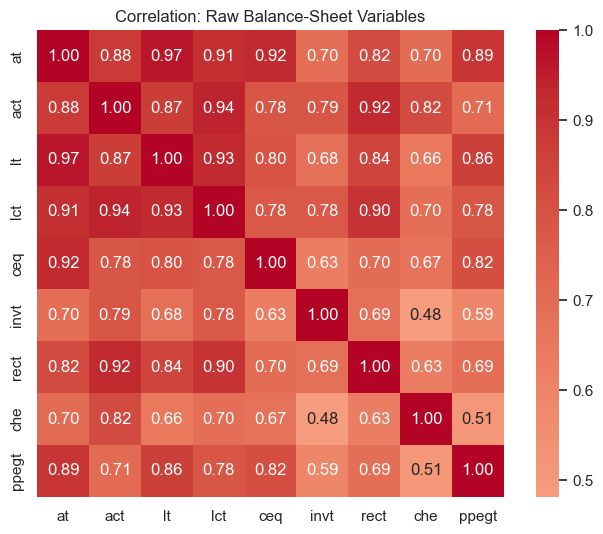

In [33]:
balance_sheet_vars = ["at", "act", "lt", "lct", "ceq", "invt", "rect", "che", "ppegt"]
corr_bs = df[balance_sheet_vars].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr_bs, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, square=True)
ax.set_title("Correlation: Raw Balance-Sheet Variables")
plt.tight_layout()
plt.show()


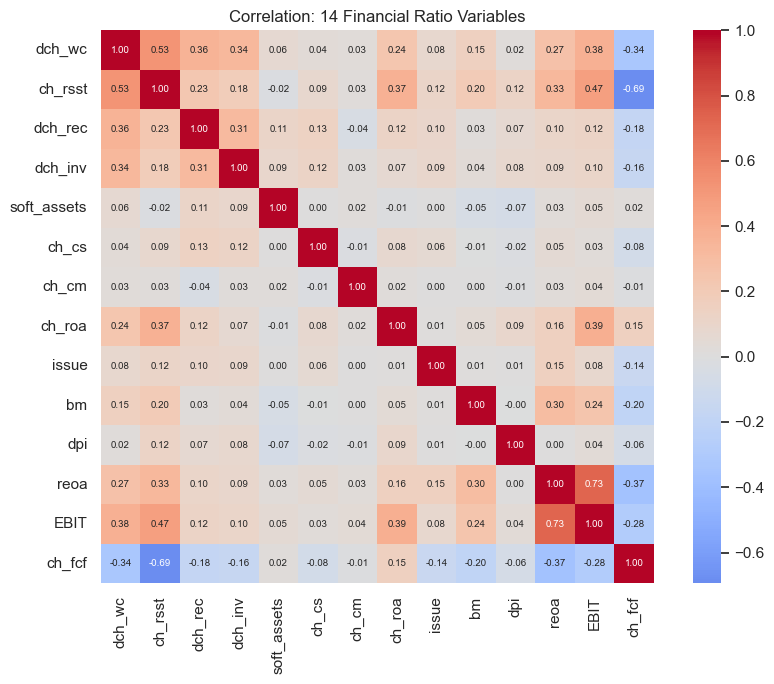

In [34]:
corr_ratios = df[ratio_vars].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_ratios, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, square=True,
            annot_kws={"size": 7})
ax.set_title("Correlation: 14 Financial Ratio Variables")
plt.tight_layout()
plt.show()


In [35]:
bs_corr_unstacked = corr_bs.where(~np.eye(len(corr_bs), dtype=bool)).unstack().dropna()
strongest_bs_pair = bs_corr_unstacked.abs().idxmax()
strongest_bs_value = bs_corr_unstacked[strongest_bs_pair]

show(
    f"**Strongest pairwise correlation among the raw balance-sheet variables shown above:** "
    f"`{strongest_bs_pair[0]}` & `{strongest_bs_pair[1]}` (r = {strongest_bs_value:.2f})"
)


**Strongest pairwise correlation among the raw balance-sheet variables shown above:** `at` & `lt` (r = 0.97)

In [36]:
comparison_rows = []
for c in ratio_vars:
    grp0 = df.loc[df["misstate"] == 0, c].dropna()
    grp1 = df.loc[df["misstate"] == 1, c].dropna()
    comparison_rows.append({
        "variable": c,
        "n_misstate_0": len(grp0),
        "n_misstate_1": len(grp1),
        "mean_misstate_0": grp0.mean(),
        "mean_misstate_1": grp1.mean(),
        "median_misstate_0": grp0.median(),
        "median_misstate_1": grp1.median(),
    })
comparison_table = pd.DataFrame(comparison_rows).set_index("variable")
comparison_table


,n_misstate_0,n_misstate_1,mean_misstate_0,mean_misstate_1,median_misstate_0,median_misstate_1
variable,,,,,,
dch_wc,140339,947,-0.005,0.024,0.004,0.011
ch_rsst,140250,944,0.018,0.093,0.026,0.053
dch_rec,140351,951,0.013,0.038,0.005,0.018
dch_inv,140481,949,0.007,0.020,0.000,0.002
soft_assets,144489,964,0.499,0.635,0.523,0.684
ch_cs,129205,922,0.184,0.382,0.068,0.151
ch_cm,128019,919,-0.091,-0.095,-0.023,-0.027
ch_roa,132443,924,-0.010,-0.013,-0.002,-0.005
issue,145081,964,0.863,0.963,1.000,1.000


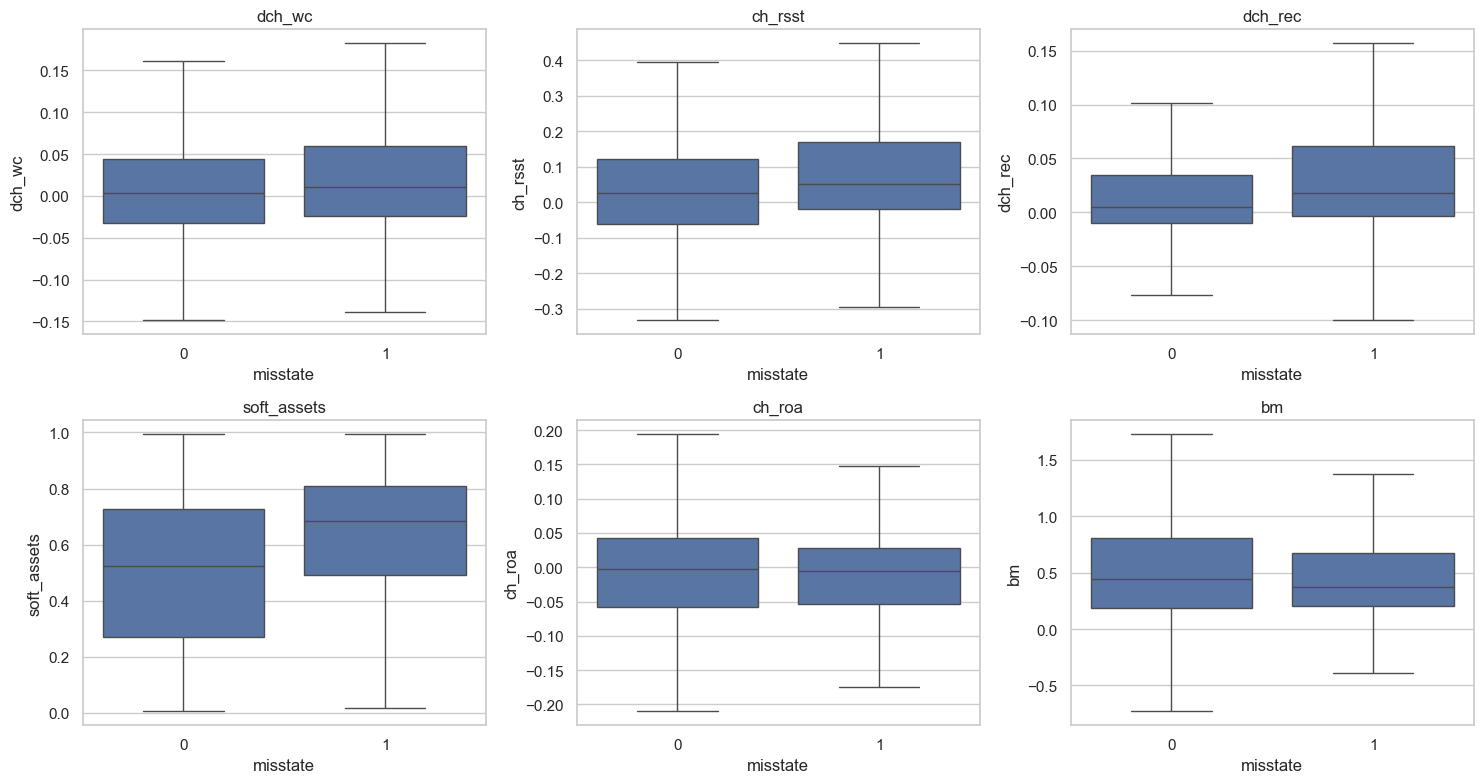

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
highlight_vars = ["dch_wc", "ch_rsst", "dch_rec", "soft_assets", "ch_roa", "bm"]
for ax, col in zip(axes.flat, highlight_vars):
    sns.boxplot(data=df, x="misstate", y=col, ax=ax, showfliers=False)
    ax.set_xticklabels(["0", "1"])
    ax.set_title(col)
plt.tight_layout()
plt.show()


In [38]:
year_summary[["n_obs", "n_positive", "positive_rate_pct"]]


,n_obs,n_positive,positive_rate_pct
fyear,,,
1990,4582,15,0.327
1991,4713,27,0.573
1992,4970,26,0.523
1993,5377,30,0.558
1994,5684,23,0.405
1995,6230,22,0.353
1996,6745,33,0.489
1997,6789,42,0.619
1998,6716,56,0.834


In [39]:
rate_std = year_summary["positive_rate_pct"].std()
rate_range = year_summary["positive_rate_pct"].max() - year_summary["positive_rate_pct"].min()

show(
    f"**Standard deviation of the yearly positive rate:** {rate_std:.3f} percentage points  \n"
    f"**Range (max - min) of the yearly positive rate:** {rate_range:.3f} percentage points"
)


**Standard deviation of the yearly positive rate:** 0.345 percentage points  
**Range (max - min) of the yearly positive rate:** 1.203 percentage points

In [40]:
company_label_stats = df.groupby("gvkey")["misstate"].agg(["nunique", "sum", "count"])
company_label_stats.columns = ["n_distinct_labels", "n_positive_years", "n_total_years"]

n_companies_both_labels = int((company_label_stats["n_distinct_labels"] > 1).sum())
n_companies_any_positive = int((company_label_stats["n_positive_years"] > 0).sum())
n_companies_total = int(len(company_label_stats))
median_years_per_company = company_label_stats["n_total_years"].median()

company_structure_summary = pd.DataFrame({
    "Metric": [
        "Total unique companies",
        "Median years of history per company",
        "Companies with at least one positive (misstate=1) year",
        "Companies with BOTH positive and negative years",
    ],
    "Value": [n_companies_total, median_years_per_company, n_companies_any_positive, n_companies_both_labels],
})
company_structure_summary


,Metric,Value
0,Total unique companies,"18,444.000"
1,Median years of history per company,6.000
2,Companies with at least one positive (misstate...,402.000
3,Companies with BOTH positive and negative years,379.000


In [41]:
# Re-verify the p_aaer <-> misstate relationship explicitly for the leakage decision
# (already shown in Section 7; repeated here because it is the basis for an explicit
# EXCLUDE decision below).
paaer_is_label_proxy = (
    ((df["p_aaer"].notna()) & (df["misstate"] == 0)).sum() == 0
    and ((df["p_aaer"].isna()) & (df["misstate"] == 1)).sum() == 0
)
show(
    f"**Is `p_aaer` non-null if and only if `misstate == 1`?** {paaer_is_label_proxy}  \n"
    f"(Verified programmatically — see Section 7 for the underlying counts.)"
)


**Is `p_aaer` non-null if and only if `misstate == 1`?** True  
(Verified programmatically — see Section 7 for the underlying counts.)

In [42]:
leakage_table = pd.DataFrame([
    ("gvkey", "Identifier",
     "Not a financial characteristic; could let a model memorize specific companies rather than learn generalizable patterns.",
     "EXCLUDE FROM MODEL FEATURES — retain only as a grouping key for cross-validation and for identification/traceability."),
    ("fyear", "Identifier / Time",
     "Contains real temporal information; the target's base rate drifts across fiscal years (Section 21), so naive use as an unordered categorical feature risks the model exploiting that drift rather than a genuine risk signal.",
     "INVESTIGATE in Phase 2 — consider excluding as a direct feature, or using it only to drive a time-based train/test split; not decided here."),
    ("p_aaer", "Label-derived metadata",
     "Verified programmatically above: non-null if and only if misstate==1 — a near-perfect proxy for the target itself.",
     "EXCLUDE FROM MODEL FEATURES — retain only for identification/analysis (e.g. linking to specific enforcement actions), consistent with the instruction to keep it available for identification while excluding it as a predictor."),
    ("28 raw Compustat variables", "Contemporaneous financial data",
     "Represent what was reported for that fiscal year. Under objective (A) — retrospective classification — using same-year financials to explain a same-year label is the standard, literature-consistent design. Under objective (B) — prospective prediction — this would need re-examination, since a live system may not have the finalized annual statement at the moment a prediction is needed.",
     "KEEP for objective (A) as framed in this project; REVISIT if the project's objective changes to (B)."),
    ("14 ratio/derived variables", "Contemporaneous, derived",
     "Same reasoning as the raw variables above — derived from data available as of that fiscal year under objective (A)'s framing.",
     "KEEP for objective (A) as framed in this project; REVISIT if the project's objective changes to (B)."),
], columns=["variable_or_group", "type", "reason", "decision_for_modeling"])
leakage_table


,variable_or_group,type,reason,decision_for_modeling
0,gvkey,Identifier,Not a financial characteristic; could let a mo...,EXCLUDE FROM MODEL FEATURES — retain only as a...
1,fyear,Identifier / Time,Contains real temporal information; the target...,INVESTIGATE in Phase 2 — consider excluding as...
2,p_aaer,Label-derived metadata,Verified programmatically above: non-null if a...,EXCLUDE FROM MODEL FEATURES — retain only for ...
3,28 raw Compustat variables,Contemporaneous financial data,Represent what was reported for that fiscal ye...,KEEP for objective (A) as framed in this proje...
4,14 ratio/derived variables,"Contemporaneous, derived",Same reasoning as the raw variables above — de...,KEEP for objective (A) as framed in this proje...


In [43]:
n_exact_dupes = int(df.duplicated(keep=False).sum())
n_gf_dupes = int(df.duplicated(subset=["gvkey", "fyear"], keep=False).sum())
n_missing_identifiers = int(df["gvkey"].isna().sum() + df["fyear"].isna().sum())
n_missing_target = int(df["misstate"].isna().sum())
n_raw_missing_cols = int(sum(1 for c in raw_vars if df[c].isna().sum() > 0))
n_ratio_missing_cols = int(sum(1 for c in ratio_vars if df[c].isna().sum() > 0))
implausible_neg_cols = [c for c in ["act", "che", "invt", "rect", "sale"] if (df[c] < 0).sum() > 0]
pos_rate_range = float(year_summary["positive_rate_pct"].max() - year_summary["positive_rate_pct"].min())

quality_checklist = pd.DataFrame([
    ("Completeness", "PASS" if n_raw_missing_cols == 0 else "REVIEW",
     f"{n_raw_missing_cols} of 28 raw variables have missing values; {n_ratio_missing_cols} of 14 ratio variables have missing values (Section 12)."),
    ("Uniqueness", "PASS" if (n_exact_dupes == 0 and n_gf_dupes == 0) else "INVESTIGATE",
     f"Exact duplicate rows: {n_exact_dupes}; duplicate (gvkey, fyear) combinations: {n_gf_dupes} (Section 11)."),
    ("Consistency", "PASS" if paaer_is_label_proxy else "INVESTIGATE",
     "issue empirically verified against (dltis>0 or sstk>0); p_aaer-vs-misstate alignment verified programmatically (Sections 7, 23)."),
    ("Validity (sign plausibility)", "PASS" if len(implausible_neg_cols) == 0 else "REVIEW",
     f"Columns with implausible negative values found: {implausible_neg_cols if implausible_neg_cols else 'none'} (Section 16)."),
    ("Range plausibility", "REVIEW",
     "Several ratio variables show high IQR-outlier rates warranting case-level review before modeling (Section 15)."),
    ("Target quality", "PASS" if n_missing_target == 0 else "INVESTIGATE",
     f"Missing target values: {n_missing_target}; severe class imbalance documented in Section 10."),
    ("Temporal consistency", "REVIEW" if pos_rate_range > 0 else "PASS",
     f"Positive rate range across fiscal years: {pos_rate_range:.3f} percentage points (Sections 9, 21)."),
    ("Identifier integrity", "PASS" if n_missing_identifiers == 0 else "INVESTIGATE",
     f"Missing gvkey/fyear values: {n_missing_identifiers} (Section 4)."),
    ("Potential leakage", "INVESTIGATE",
     "p_aaer and gvkey must be excluded as model features; fyear needs a Phase 2 decision (Section 23)."),
    ("Company-level independence", "INVESTIGATE" if n_companies_both_labels > 0 else "PASS",
     f"{n_companies_both_labels} companies have both labels across their history — a concrete train/test leakage consideration if greater than zero (Section 22)."),
], columns=["area", "status", "basis"])
quality_checklist


,area,status,basis
0,Completeness,PASS,0 of 28 raw variables have missing values; 13 ...
1,Uniqueness,PASS,"Exact duplicate rows: 0; duplicate (gvkey, fye..."
2,Consistency,PASS,issue empirically verified against (dltis>0 or...
3,Validity (sign plausibility),REVIEW,Columns with implausible negative values found...
4,Range plausibility,REVIEW,Several ratio variables show high IQR-outlier ...
5,Target quality,PASS,Missing target values: 0; severe class imbalan...
6,Temporal consistency,REVIEW,Positive rate range across fiscal years: 1.203...
7,Identifier integrity,PASS,Missing gvkey/fyear values: 0 (Section 4).
8,Potential leakage,INVESTIGATE,p_aaer and gvkey must be excluded as model fea...
9,Company-level independence,INVESTIGATE,379 companies have both labels across their hi...


In [44]:
observed_facts = f'''### Observed Facts

- The dataset contains {len(df):,} company-fiscal-year observations for {df["gvkey"].nunique():,} unique companies across fiscal years {df["fyear"].min()}-{df["fyear"].max()} (Sections 4, 8, 9).
- Exact duplicate rows: {n_exact_dupes}; duplicate (gvkey, fyear) combinations: {n_gf_dupes} (Section 11).
- {int(target_counts.get(1, 0)):,} observations ({pos_pct:.3f}%) carry a positive `misstate` label; `p_aaer` is non-null for exactly these rows and no others, verified programmatically (Sections 7, 10, 23).
- {n_raw_missing_cols} of the 28 raw accounting variables have any missing values; {n_ratio_missing_cols} of the 14 derived ratio variables have missing values, ranging up to {missing_table.drop(index="p_aaer", errors="ignore")["missing_pct"].max():.2f}% (Section 12).
- The yearly positive-label rate ranges by {pos_rate_range:.3f} percentage points across the sample period (Sections 9, 21).
- {n_companies_both_labels} companies have both a positive and a negative labeled year somewhere in their history; {n_companies_any_positive} companies have at least one positive year in total (Section 22).
- Columns with implausible negative values (not standard under accounting definitions): {implausible_neg_cols if implausible_neg_cols else "none found"} (Section 16).
'''
show(observed_facts)


### Observed Facts

- The dataset contains 146,045 company-fiscal-year observations for 18,444 unique companies across fiscal years 1990-2014 (Sections 4, 8, 9).
- Exact duplicate rows: 0; duplicate (gvkey, fyear) combinations: 0 (Section 11).
- 964 observations (0.660%) carry a positive `misstate` label; `p_aaer` is non-null for exactly these rows and no others, verified programmatically (Sections 7, 10, 23).
- 0 of the 28 raw accounting variables have any missing values; 13 of the 14 derived ratio variables have missing values, ranging up to 11.71% (Section 12).
- The yearly positive-label rate ranges by 1.203 percentage points across the sample period (Sections 9, 21).
- 379 companies have both a positive and a negative labeled year somewhere in their history; 402 companies have at least one positive year in total (Section 22).
- Columns with implausible negative values (not standard under accounting definitions): ['act', 'che', 'invt', 'rect', 'sale'] (Section 16).


In [45]:
readiness_table = pd.DataFrame([
    ("Target definition", "Historically AAER-associated label, not a confirmed-fraud label (Section 10)",
     "Must be communicated precisely in any findings; do not overstate label meaning."),
    ("Class balance", f"Positive rate {pos_pct:.3f}% (Section 10)",
     "Requires imbalance-aware evaluation metrics (PR-AUC, recall, precision) and possibly resampling/weighting in Phase 2."),
    ("Missing data", f"{n_raw_missing_cols} of 28 raw variables, {n_ratio_missing_cols} of 14 ratio variables affected (Section 12)",
     "Needs a documented, justified treatment decision in Phase 2 (e.g. imputation vs. exclusion), not silent dropping."),
    ("Outliers", "Present in several raw and ratio variables per Section 15; classification, not automatic evidence of error",
     "Requires case-level review, not blanket removal."),
    ("Feature distributions", "Raw dollar variables skewed per Section 13/14; ratio variables closer to usable scale",
     "Raw variables likely need transformation (log, scaling) or exclusion in favor of ratios for many model types."),
    ("Repeated companies", f"{n_companies_both_labels} companies with mixed labels across years (Section 22)",
     "Requires group-aware train/test split consideration."),
    ("Time structure", f"{df['fyear'].nunique()} fiscal years; positive rate range {pos_rate_range:.3f} pp (Section 21)",
     "Requires time-aware validation strategy consideration."),
    ("Potential leakage", "p_aaer and gvkey flagged EXCLUDE; fyear flagged INVESTIGATE (Section 23)",
     "Must exclude p_aaer and gvkey as features; decide fyear treatment before modeling."),
    ("Multicollinearity", "High correlation among several raw balance-sheet totals per Section 19; weaker among ratio variables",
     "Favor ratio variables and/or apply feature selection/regularization in Phase 2."),
    ("Feature availability", "All 42 financial variables are contemporaneous, consistent with the objective-(A) framing in Section 23",
     "Re-confirm this framing before modeling; revisit if objective changes to prospective prediction (B)."),
    ("Data quality", "See Section 24 checklist for the current PASS/REVIEW/INVESTIGATE status of each area",
     "Proceed to Phase 2 cleaning with documented decisions for each REVIEW/INVESTIGATE item."),
], columns=["area", "assessment", "implication"])
readiness_table


,area,assessment,implication
0,Target definition,"Historically AAER-associated label, not a conf...",Must be communicated precisely in any findings...
1,Class balance,Positive rate 0.660% (Section 10),Requires imbalance-aware evaluation metrics (P...
2,Missing data,"0 of 28 raw variables, 13 of 14 ratio variable...","Needs a documented, justified treatment decisi..."
3,Outliers,Present in several raw and ratio variables per...,"Requires case-level review, not blanket removal."
4,Feature distributions,Raw dollar variables skewed per Section 13/14;...,"Raw variables likely need transformation (log,..."
5,Repeated companies,379 companies with mixed labels across years (...,Requires group-aware train/test split consider...
6,Time structure,25 fiscal years; positive rate range 1.203 pp ...,Requires time-aware validation strategy consid...
7,Potential leakage,p_aaer and gvkey flagged EXCLUDE; fyear flagge...,Must exclude p_aaer and gvkey as features; dec...
8,Multicollinearity,High correlation among several raw balance-she...,Favor ratio variables and/or apply feature sel...
9,Feature availability,All 42 financial variables are contemporaneous...,Re-confirm this framing before modeling; revis...


In [46]:
n_investigate = int((quality_checklist["status"] == "INVESTIGATE").sum())
n_review = int((quality_checklist["status"] == "REVIEW").sum())

show(
    f"**Data quality checklist status counts:** {n_investigate} INVESTIGATE, {n_review} REVIEW, "
    f"{int((quality_checklist['status'] == 'PASS').sum())} PASS (Section 24).  \n\n"
    "**Is the dataset ready for modeling?** Not yet — the counts above show open "
    "REVIEW/INVESTIGATE items. No fundamental blocker was identified (e.g., no missing "
    "target values, no duplicate rows), but Phase 2 must first make and document "
    "explicit decisions for each REVIEW/INVESTIGATE item before feature engineering or "
    "model training begins."
)


**Data quality checklist status counts:** 2 INVESTIGATE, 3 REVIEW, 5 PASS (Section 24).  

**Is the dataset ready for modeling?** Not yet — the counts above show open REVIEW/INVESTIGATE items. No fundamental blocker was identified (e.g., no missing target values, no duplicate rows), but Phase 2 must first make and document explicit decisions for each REVIEW/INVESTIGATE item before feature engineering or model training begins.

In [47]:
final_summary = f'''### What we know

- One row = one company-fiscal-year observation (verified in Section 4): {len(df):,} rows, {df["gvkey"].nunique():,} companies, fiscal years {df["fyear"].min()}-{df["fyear"].max()}, {n_exact_dupes} exact duplicates, {n_gf_dupes} duplicate (gvkey, fyear) pairs.
- Target (`misstate`) positive rate is {pos_pct:.3f}%; it represents historical AAER-association, not confirmed fraud.
- {n_raw_missing_cols} of 28 raw variables and {n_ratio_missing_cols} of 14 ratio variables have any missingness.
- `issue` and the `p_aaer`/`misstate` relationship were both empirically verified rather than assumed (Sections 7, 23).
- {n_companies_both_labels} companies have mixed labels across their history — a concrete train/test leakage consideration if addressed naively.
- The yearly positive rate varies by {pos_rate_range:.3f} percentage points across the sample.

### What we do not yet know

- The specific cause of the implausible negative values identified in Section 16.
- The optimal train/test split strategy for Phase 2 (group-based, time-based, or combined) — this notebook surfaces the evidence but does not decide it.
- The final feature list for modeling (raw vs. ratio variables, treatment of `fyear`).

### What needs cleaning

- Documented handling of missingness in the ratio variables identified in Section 12.
- Case-level review of the implausible negative values identified in Section 16.

### What needs investigation

- The outlier-heavy ratio variables identified in Section 15.
- Whether `fyear` should be a direct feature, dropped, or split-only (Section 23) — framed there, not resolved.

### Modeling considerations

- Prefer ratio variables over raw dollar variables to reduce firm-size effects and multicollinearity (Section 19).
- Use imbalance-aware evaluation metrics; plain accuracy is not informative at this base rate (Section 10).
- Exclude `p_aaer` and `gvkey` from features; treat `gvkey` as a grouping variable only (Section 23).
- Re-confirm the retrospective-classification framing (Section 1, 23) before finalizing the feature set, since a prospective early-warning objective would require different availability assumptions.

### Next phase

Phase 2 (`02_data_cleaning_eda.ipynb`) will focus on: making and documenting justified decisions for the missing-value and negative/outlier items flagged as REVIEW/INVESTIGATE here, finalizing the feature set consistent with the leakage decisions in Section 23, refining exploratory analysis on the cleaned data, and preparing the data for the Phase 1 misstatement-risk model — without yet training any model or reporting any performance numbers.
'''
show(final_summary)


### What we know

- One row = one company-fiscal-year observation (verified in Section 4): 146,045 rows, 18,444 companies, fiscal years 1990-2014, 0 exact duplicates, 0 duplicate (gvkey, fyear) pairs.
- Target (`misstate`) positive rate is 0.660%; it represents historical AAER-association, not confirmed fraud.
- 0 of 28 raw variables and 13 of 14 ratio variables have any missingness.
- `issue` and the `p_aaer`/`misstate` relationship were both empirically verified rather than assumed (Sections 7, 23).
- 379 companies have mixed labels across their history — a concrete train/test leakage consideration if addressed naively.
- The yearly positive rate varies by 1.203 percentage points across the sample.

### What we do not yet know

- The specific cause of the implausible negative values identified in Section 16.
- The optimal train/test split strategy for Phase 2 (group-based, time-based, or combined) — this notebook surfaces the evidence but does not decide it.
- The final feature list for modeling (raw vs. ratio variables, treatment of `fyear`).

### What needs cleaning

- Documented handling of missingness in the ratio variables identified in Section 12.
- Case-level review of the implausible negative values identified in Section 16.

### What needs investigation

- The outlier-heavy ratio variables identified in Section 15.
- Whether `fyear` should be a direct feature, dropped, or split-only (Section 23) — framed there, not resolved.

### Modeling considerations

- Prefer ratio variables over raw dollar variables to reduce firm-size effects and multicollinearity (Section 19).
- Use imbalance-aware evaluation metrics; plain accuracy is not informative at this base rate (Section 10).
- Exclude `p_aaer` and `gvkey` from features; treat `gvkey` as a grouping variable only (Section 23).
- Re-confirm the retrospective-classification framing (Section 1, 23) before finalizing the feature set, since a prospective early-warning objective would require different availability assumptions.

### Next phase

Phase 2 (`02_data_cleaning_eda.ipynb`) will focus on: making and documenting justified decisions for the missing-value and negative/outlier items flagged as REVIEW/INVESTIGATE here, finalizing the feature set consistent with the leakage decisions in Section 23, refining exploratory analysis on the cleaned data, and preparing the data for the Phase 1 misstatement-risk model — without yet training any model or reporting any performance numbers.
